# Path Divergence Metrics

This notebook compares two paths between fixed markers on different elevation crops. We compute **shape-based** and **alignment-based** metrics that quantify how far the paths diverge, and we normalize most metrics by the straight-line distance between markers so they are less sensitive to resolution.

Key ideas:
- **Hausdorff / Fréchet / DTW** capture pointwise and ordering-aware deviations.
- **Area-based metrics** capture global divergence normalized by marker distance or path length.
- **Chamfer (mean deviation)** captures average nearest-neighbor discrepancy.

References used to select metrics:
- Hausdorff distance: https://en.wikipedia.org/wiki/Hausdorff_distance
- Fréchet distance (discrete version): https://en.wikipedia.org/wiki/Fr%C3%A9chet_distance
- Dynamic Time Warping (DTW): https://en.wikipedia.org/wiki/Dynamic_time_warping

In [1]:
import json
import logging
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from loguru import logger as loguru_logger

# Configure info logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(name)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)

# Configure loguru for info level
loguru_logger.remove()
loguru_logger.add(sys.stderr, level="INFO")

# Add src to path for imports
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from passage.generate import find_path, load_tile_grid, _resolve_solver_config
from passage.visualization import tensor_to_image
from scipy.spatial.distance import directed_hausdorff

In [3]:
# Configuration
CONFIG_PATH = ROOT / "config" / "config.yaml"
TILES_DIR = ROOT / "outputs" / "download" / "tiles"
CALIBRATE_PATH = ROOT / "outputs" / "calibrate" / "calibrate.json"

RESOLUTION = 256  # Resolution of elevation maps
DEFAULT_COST_MODEL = "elevation"

# Load config
try:
    with open(CONFIG_PATH) as f:
        _config = yaml.safe_load(f) or {}
    _solver_cfg = _config.get("solver", {})
    COST_MODEL = (
        _solver_cfg.get("grid", {}).get("cost_model")
        or _solver_cfg.get("networkx", {}).get("cost_model")
        or _solver_cfg.get("pathfinding", {}).get("cost_model")
        or DEFAULT_COST_MODEL
    )
except Exception:
    COST_MODEL = DEFAULT_COST_MODEL

# Solver config for path finding
SOLVER_CONFIG = _resolve_solver_config(_solver_cfg)

In [4]:
# Load calibration data
if not CALIBRATE_PATH.exists():
    raise FileNotFoundError(f"Calibration file not found: {CALIBRATE_PATH}. Run 'passage calibrate' first.")
if not TILES_DIR.exists():
    raise FileNotFoundError(f"Tiles directory not found: {TILES_DIR}. Run 'passage download' first.")

with open(CALIBRATE_PATH) as f:
    calibration = json.load(f)

global_min = float(calibration["global_min"])
global_max = float(calibration["global_max"])
tile_stats_df = pd.DataFrame(calibration["tile_stats"])

print(f"Global elevation range: [{global_min:.1f}, {global_max:.1f}]")
print(f"Number of tiles: {len(tile_stats_df)}")

Global elevation range: [-430.0, 8767.0]
Number of tiles: 23993


## Helpers

Functions to generate elevation crops, compute paths, and derive metric helpers.

In [5]:
import math
import random

TILE_SIZE_PX = 3600


def generate_random_crop(
    resolution: int,
    tile_stats_df: pd.DataFrame,
    tiles_dirpath: Path,
    global_min: float,
    global_max: float,
    seed: int | None = None,
) -> np.ndarray | None:
    """Generate a random elevation crop of the given resolution.

    Returns:
        Elevation crop as numpy array, or None if generation failed.
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    half_res = resolution // 2
    half_tiles = max(1, math.ceil(half_res / TILE_SIZE_PX))

    for _ in range(10):  # Try up to 10 times
        # Pick a random elevation
        target_elev = random.uniform(global_min, global_max)

        # Filter tiles containing this elevation
        candidates = tile_stats_df[(tile_stats_df["min"] <= target_elev) & (tile_stats_df["max"] >= target_elev)]

        if candidates.empty:
            continue

        # Select random tile
        selected = candidates.sample(n=1).iloc[0]
        center_lat = int(selected["lat"])
        center_lon = int(selected["lon"])

        # Load tile grid
        grid = load_tile_grid(tiles_dirpath, center_lat, center_lon, half_tiles=half_tiles)
        grid_h, grid_w = grid.shape

        if grid_h < resolution or grid_w < resolution:
            continue

        # Random crop position
        y1 = random.randint(0, grid_h - resolution)
        x1 = random.randint(0, grid_w - resolution)

        crop = grid[y1 : y1 + resolution, x1 : x1 + resolution]
        return crop

    return None


def get_marker_positions(resolution: int) -> tuple[tuple[int, int], tuple[int, int]]:
    """Get fixed marker positions at 0.2 and 0.8 of resolution.

    Returns:
        (start, end) marker positions as (row, col) tuples.
    """
    pos1 = int(0.2 * resolution)
    pos2 = int(0.8 * resolution)
    start = (pos1, pos1)
    end = (pos2, pos2)
    return start, end


print(f"Marker positions for resolution {RESOLUTION}: {get_marker_positions(RESOLUTION)}")

Marker positions for resolution 256: ((51, 51), (204, 204))


## Compute a Single Case (paths first)

Generate two different elevation crops, compute both paths, then compute metrics, then visualize.

In [6]:
# Generate two different elevation crops
crop1 = generate_random_crop(RESOLUTION, tile_stats_df, TILES_DIR, global_min, global_max, seed=42)
crop2 = generate_random_crop(RESOLUTION, tile_stats_df, TILES_DIR, global_min, global_max, seed=123)

if crop1 is None or crop2 is None:
    raise RuntimeError("Failed to generate elevation crops")

# Get marker positions
start, end = get_marker_positions(RESOLUTION)
print(f"Start marker: {start}")
print(f"End marker: {end}")

# Find paths (compute both before metrics)
path1 = find_path(crop1, start, end, SOLVER_CONFIG)
path2 = find_path(crop2, start, end, SOLVER_CONFIG)

print(f"Path 1 length: {len(path1)} pixels")
print(f"Path 2 length: {len(path2)} pixels")

Start marker: (51, 51)
End marker: (204, 204)
Path 1 length: 163 pixels
Path 2 length: 172 pixels


In [7]:
def draw_paths_on_black(path1: list, path2: list, resolution: int) -> np.ndarray:
    """Draw two paths on a black background.

    Args:
        path1: First path as list of (row, col) tuples
        path2: Second path as list of (row, col) tuples
        resolution: Image resolution

    Returns:
        RGB image with paths drawn
    """
    # Create black background (RGB)
    img = np.zeros((resolution, resolution, 3), dtype=np.uint8)

    # Draw path 1 in blue
    if len(path1) > 0:
        path1_arr = np.array(path1)
        # OpenCV uses (x, y) = (col, row) format
        pts1 = path1_arr[:, ::-1].reshape((-1, 1, 2)).astype(np.int32)
        cv2.polylines(img, [pts1], isClosed=False, color=(0, 0, 255), thickness=2)

    # Draw path 2 in red
    if len(path2) > 0:
        path2_arr = np.array(path2)
        pts2 = path2_arr[:, ::-1].reshape((-1, 1, 2)).astype(np.int32)
        cv2.polylines(img, [pts2], isClosed=False, color=(255, 0, 0), thickness=2)

    return img


def make_vis_from_crop(crop, path, resolution):
    elevation_norm = (crop - global_min) / (global_max - global_min)
    elevation_norm = np.clip(elevation_norm, 0.0, 1.0).astype(np.float32)
    marker_channel = np.full_like(elevation_norm, -1.0, dtype=np.float32)
    start_pos, end_pos = get_marker_positions(resolution)
    marker_channel[start_pos] = 0.0
    marker_channel[end_pos] = 1.0
    obstacles_channel = np.zeros_like(elevation_norm, dtype=np.float32)
    tensor_vis = np.stack([elevation_norm, marker_channel, obstacles_channel], axis=-1)
    img_bgr = tensor_to_image(tensor_vis, path_pixels=path)
    return img_bgr[:, :, ::-1]

## Geometry Helpers

Utilities to compute area between paths and point-to-path distances (used later for visualization).

In [8]:
def compute_area_between_paths(path1: list, path2: list, resolution: int) -> tuple[int, np.ndarray]:
    """Compute the area (in pixels) between two paths using OpenCV.

    The area is computed by:
    1. Creating a closed polygon from path1 -> reversed(path2)
    2. Filling the polygon and counting pixels

    Args:
        path1: First path as list of (row, col) tuples
        path2: Second path as list of (row, col) tuples
        resolution: Image resolution

    Returns:
        (area_pixels, mask) where mask is the filled area visualization
    """
    if len(path1) == 0 or len(path2) == 0:
        return 0, np.zeros((resolution, resolution), dtype=np.uint8)

    # Create a closed polygon: path1 followed by reversed path2
    path1_arr = np.array(path1)
    path2_arr = np.array(path2)

    # Combine paths to form a closed contour
    # path1: start -> end, path2 reversed: end -> start
    combined = np.vstack([path1_arr, path2_arr[::-1]])

    # Convert to OpenCV format (col, row)
    pts = combined[:, ::-1].astype(np.int32)

    # Create mask and fill polygon
    mask = np.zeros((resolution, resolution), dtype=np.uint8)
    cv2.fillPoly(mask, [pts], color=255)

    # Count pixels
    area_pixels = np.sum(mask > 0)

    return area_pixels, mask

In [ ]:
def visualize_single_case(crop1, crop2, path1, path2, resolution: int) -> None:
    """Visualize paths and area between them for a single case."""
    draw_paths_on_black(path1, path2, resolution)
    area_pixels, area_mask = compute_area_between_paths(path1, path2, resolution)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(make_vis_from_crop(crop1, path1, resolution))
    axes[0].set_title("Elevation 1 + Path 1")
    axes[0].axis("off")

    axes[1].imshow(make_vis_from_crop(crop2, path2, resolution))
    axes[1].set_title("Elevation 2 + Path 2")
    axes[1].axis("off")

    # Area between paths (filled polygon)
    axes[2].imshow(area_mask, cmap="hot", origin="upper")
    axes[2].set_title(f"Area Between Paths: {int(area_pixels)} px")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

## Metric Functions

Definitions for path comparison metrics (used for single-case and batch evaluation).

In [10]:
def compute_path_divergence_metric(path1: list, path2: list, resolution: int) -> dict:
    """Compute path divergence metric: area between paths / bounding box area.

    Args:
        path1: First path as list of (row, col) tuples
        path2: Second path as list of (row, col) tuples
        resolution: Image resolution

    Returns:
        Dictionary with metrics:
            - area_pixels: Number of pixels between paths
            - bbox_area: Bounding box area in pixels
            - bbox: (min_row, min_col, max_row, max_col)
            - divergence_ratio: area_pixels / bbox_area
    """
    if len(path1) == 0 or len(path2) == 0:
        return {
            "area_pixels": 0,
            "bbox_area": 0,
            "bbox": (0, 0, 0, 0),
            "divergence_ratio": 0.0,
        }

    # Compute area between paths
    area_pixels, _ = compute_area_between_paths(path1, path2, resolution)

    # Compute bounding box encompassing both paths
    path1_arr = np.array(path1)
    path2_arr = np.array(path2)
    all_points = np.vstack([path1_arr, path2_arr])

    min_row = int(all_points[:, 0].min())
    max_row = int(all_points[:, 0].max())
    min_col = int(all_points[:, 1].min())
    max_col = int(all_points[:, 1].max())

    bbox_height = max_row - min_row + 1
    bbox_width = max_col - min_col + 1
    bbox_area = bbox_height * bbox_width

    # Compute divergence ratio
    divergence_ratio = area_pixels / bbox_area if bbox_area > 0 else 0.0

    return {
        "area_pixels": area_pixels,
        "bbox_area": bbox_area,
        "bbox": (min_row, min_col, max_row, max_col),
        "divergence_ratio": divergence_ratio,
    }

In [11]:
def report_single_case_metrics(path1: list, path2: list, resolution: int) -> dict:
    """Compute and print metrics for the single example."""
    single_metrics = compute_all_metrics(path1, path2, resolution)
    print("Single-case metrics:")
    for name, value in single_metrics.items():
        print(f"  {name}: {value:.4f}")
    return single_metrics

## Metrics Summary (matches functions below)

Let $P=(p_1,\dots,p_n)$ and $Q=(q_1,\dots,q_m)$ be the two paths as ordered point sequences.
Define $D=\lVert p_1-p_n\rVert_2$ (straight-line marker distance), and $A$ the filled area between paths.
We normalize by $D$ (or $D^2$ for areas) to reduce resolution sensitivity.

### Metrics computed
- **normalized_hausdorff_distance**: $H/D$ where $H$ is the Hausdorff distance.
- **scaled_hausdorff_distance**: $H/\tfrac{1}{2}(n+m)$ (normalizes by mean path length).
- **normalized_hausdorff_area**: $(H_1\cdot H_2)/D^2$ where $H_1,H_2$ are directed Hausdorff distances.
- **scaled_hausdorff_area**: $(H_1\cdot H_2)/(	frac{1}{2}(n+m))^2$.
- **normalized_area_between_paths**: $A/D^2$.
- **scaled_area_between_paths**: $A/(	frac{1}{2}(n+m))^2$.
- **chamfer_distance** (mean deviation): $\frac{\overline{d(P\to Q)}+\overline{d(Q\to P)}}{2D}$.
- **normalized_discrete_frechet_distance**: $F_d/D$ where $F_d$ is discrete Fréchet distance.
- **normalized_dtw_distance**: $\mathrm{DTW}/(\max(n,m)\,D)$.

In [12]:
def _marker_distance(path1: list, path2: list) -> float:
    """Straight-line marker distance (used for normalization)."""
    if len(path1) > 0:
        start = np.array(path1[0])
        end = np.array(path1[-1])
    elif len(path2) > 0:
        start = np.array(path2[0])
        end = np.array(path2[-1])
    else:
        return 0.0
    return float(np.linalg.norm(end - start))


def hausdorff_distance(path1: list, path2: list) -> float:
    """Compute Hausdorff distance between two paths using scipy."""
    if len(path1) == 0 or len(path2) == 0:
        return 0.0
    arr1 = np.array(path1)
    arr2 = np.array(path2)
    d1 = directed_hausdorff(arr1, arr2)[0]
    d2 = directed_hausdorff(arr2, arr1)[0]
    return max(d1, d2)


def normalized_hausdorff_distance(path1: list, path2: list) -> float:
    """Compute normalized Hausdorff distance."""
    haus = hausdorff_distance(path1, path2)
    dist = _marker_distance(path1, path2)
    return haus / max(dist, 1e-6)


def scaled_hausdorff_distance(path1: list, path2: list) -> float:
    """Compute Hausdorff distance normalized by mean path length."""
    haus = hausdorff_distance(path1, path2)
    dist = 0.5 * (len(path1) + len(path2))
    return haus / max(dist, 1e-6)


def hausdorff_area(path1: list, path2: list) -> float:
    if len(path1) == 0 or len(path2) == 0:
        return 0.0
    arr1 = np.array(path1)
    arr2 = np.array(path2)
    d1 = directed_hausdorff(arr1, arr2)[0]
    d2 = directed_hausdorff(arr2, arr1)[0]
    return d1 * d2


def normalized_hausdorff_area(path1: list, path2: list) -> float:
    haus_area = hausdorff_area(path1, path2)
    dist = _marker_distance(path1, path2)
    return haus_area / max(dist**2, 1e-6)


def scaled_hausdorff_area(path1: list, path2: list) -> float:
    haus_area = hausdorff_area(path1, path2)
    dist = 0.5 * (len(path1) + len(path2))
    return haus_area / max(dist**2, 1e-6)


def area_between_paths(path1: list, path2: list, resolution: int) -> float:
    area_pixels, _ = compute_area_between_paths(path1, path2, resolution)
    return area_pixels


def normalized_area_between_paths(path1: list, path2: list, resolution: int) -> float:
    area_pixels = area_between_paths(path1, path2, resolution)
    dist = _marker_distance(path1, path2)
    return area_pixels / max(dist**2, 1e-6)


def scaled_area_between_paths(path1: list, path2: list, resolution: int) -> float:
    area_pixels = area_between_paths(path1, path2, resolution)
    dist = 0.5 * (len(path1) + len(path2))
    return area_pixels / max(dist**2, 1e-6)


def _mean_min_distance(arr_a: np.ndarray, arr_b: np.ndarray) -> float:
    """Mean of nearest-neighbor distances from arr_a to arr_b."""
    if len(arr_a) == 0 or len(arr_b) == 0:
        return 0.0
    dists = []
    for p in arr_a:
        dists.append(np.min(np.sqrt(np.sum((arr_b - p) ** 2, axis=1))))
    return float(np.mean(dists))


def mean_deviation(path1: list, path2: list, resolution: int) -> float:
    """Average mean point-to-path distance in normalized units."""
    if len(path1) == 0 or len(path2) == 0:
        return 0.0
    arr1 = np.array(path1)
    arr2 = np.array(path2)
    d1 = _mean_min_distance(arr1, arr2)
    d2 = _mean_min_distance(arr2, arr1)
    dist = _marker_distance(path1, path2)
    return (d1 + d2) / (2 * max(dist, 1e-6))


def chamfer_distance(path1: list, path2: list, resolution: int) -> float:
    """Symmetric Chamfer distance (normalized)."""
    return mean_deviation(path1, path2, resolution)


def discrete_frechet_distance(path1: list, path2: list) -> float:
    """Discrete Fréchet distance (Eiter & Mannila, 1994)."""
    if len(path1) == 0 or len(path2) == 0:
        return 0.0
    P = np.array(path1)
    Q = np.array(path2)
    n, m = len(P), len(Q)
    ca = np.full((n, m), -1.0, dtype=np.float64)

    def _c(i: int, j: int) -> float:
        if ca[i, j] > -1:
            return ca[i, j]
        d = np.linalg.norm(P[i] - Q[j])
        if i == 0 and j == 0:
            ca[i, j] = d
        elif i > 0 and j == 0:
            ca[i, j] = max(_c(i - 1, 0), d)
        elif i == 0 and j > 0:
            ca[i, j] = max(_c(0, j - 1), d)
        elif i > 0 and j > 0:
            ca[i, j] = max(min(_c(i - 1, j), _c(i - 1, j - 1), _c(i, j - 1)), d)
        else:
            ca[i, j] = np.inf
        return ca[i, j]

    return float(_c(n - 1, m - 1))


def normalized_discrete_frechet_distance(path1: list, path2: list) -> float:
    dist = _marker_distance(path1, path2)
    return discrete_frechet_distance(path1, path2) / max(dist, 1e-6)


def dtw_distance(path1: list, path2: list) -> float:
    """Dynamic Time Warping distance for 2D point sequences."""
    if len(path1) == 0 or len(path2) == 0:
        return 0.0
    P = np.array(path1)
    Q = np.array(path2)
    n, m = len(P), len(Q)
    dtw = np.full((n + 1, m + 1), np.inf, dtype=np.float64)
    dtw[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = np.linalg.norm(P[i - 1] - Q[j - 1])
            dtw[i, j] = cost + min(dtw[i - 1, j], dtw[i, j - 1], dtw[i - 1, j - 1])
    return float(dtw[n, m])


def normalized_dtw_distance(path1: list, path2: list) -> float:
    dist = _marker_distance(path1, path2)
    denom = max(len(path1), len(path2), 1) * max(dist, 1e-6)
    return dtw_distance(path1, path2) / denom


def scaled_area(path1: list, path2: list, resolution: int) -> float:
    area = area_between_paths(path1, path2, resolution)
    norm_area = max((max(len(path1), len(path2)) ** 2), 1)
    haus = hausdorff_distance(path1, path2)
    norm_haus = max(max(len(path1), len(path2)), 1)
    return area / norm_area * (haus / norm_haus + 1)


def compute_all_metrics(path1: list, path2: list, resolution: int) -> dict:
    """Compute path comparison metrics. Some are similarity scores, others are distances."""
    return {
        "normalized_hausdorff_distance": normalized_hausdorff_distance(path1, path2),
        "scaled_hausdorff_distance": scaled_hausdorff_distance(path1, path2),
        "normalized_hausdorff_area": normalized_hausdorff_area(path1, path2),
        "scaled_hausdorff_area": scaled_hausdorff_area(path1, path2),
        "normalized_area_between_paths": normalized_area_between_paths(path1, path2, resolution),
        "scaled_area_between_paths": scaled_area_between_paths(path1, path2, resolution),
        "chamfer_distance": chamfer_distance(path1, path2, resolution),
        "normalized_discrete_frechet_distance": normalized_discrete_frechet_distance(path1, path2),
        "normalized_dtw_distance": normalized_dtw_distance(path1, path2),
        "scaled_area": scaled_area(path1, path2, resolution),
    }

## Single Case: Metrics + Visualization

Compute metrics for the single example, then visualize.

Single-case metrics:
  normalized_hausdorff_distance: 0.0131
  scaled_hausdorff_distance: 0.0169
  normalized_hausdorff_area: 0.0002
  scaled_hausdorff_area: 0.0003
  normalized_area_between_paths: 0.0091
  scaled_area_between_paths: 0.0152
  chamfer_distance: 0.0057
  normalized_discrete_frechet_distance: 0.0131
  normalized_dtw_distance: 0.0059
  scaled_area: 0.0146


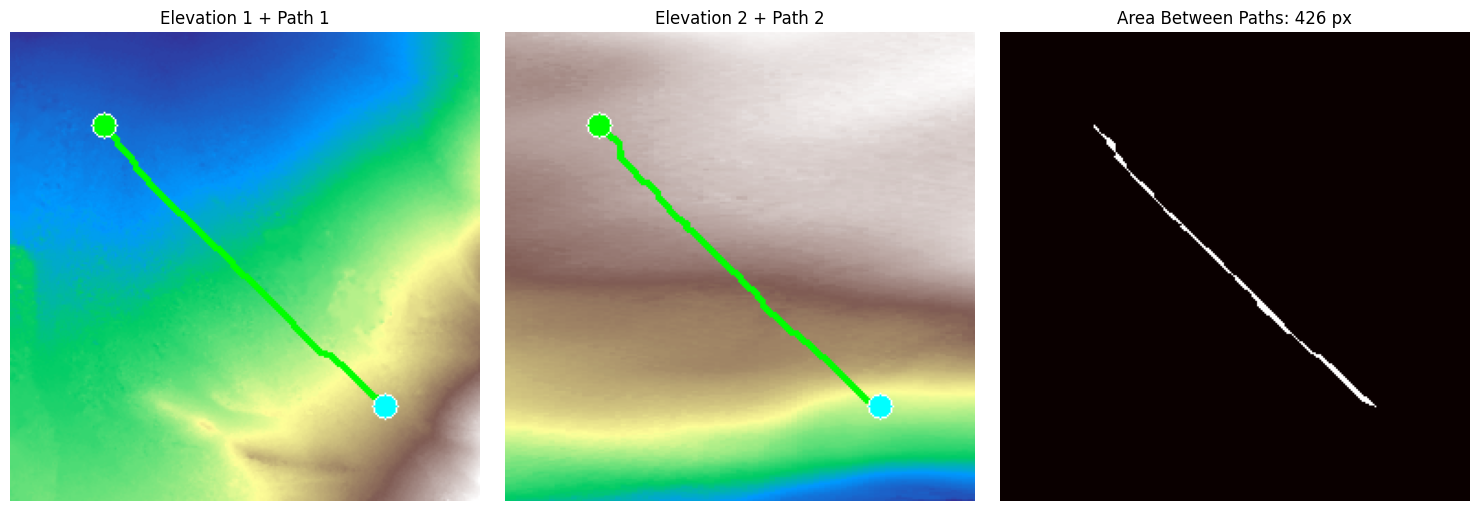

In [13]:
single_metrics = report_single_case_metrics(path1, path2, RESOLUTION)
visualize_single_case(crop1, crop2, path1, path2, RESOLUTION)

## Generate Path Pair Cases

Generate multiple cases, compute paths first, then metrics and visualizations.

In [14]:
from tqdm import tqdm


NUM_CASES = 20

cases = []

for i in tqdm(range(NUM_CASES)):
    seed1 = i * 1000
    seed2 = i * 1000 + 500

    crop1 = generate_random_crop(RESOLUTION, tile_stats_df, TILES_DIR, global_min, global_max, seed=seed1)
    crop2 = generate_random_crop(RESOLUTION, tile_stats_df, TILES_DIR, global_min, global_max, seed=seed2)

    if crop1 is None or crop2 is None:
        print(f"Case {i + 1}: Failed to generate crops, skipping")
        continue

    start, end = get_marker_positions(RESOLUTION)
    path1 = find_path(crop1, start, end, SOLVER_CONFIG)
    path2 = find_path(crop2, start, end, SOLVER_CONFIG)

    if len(path1) == 0 or len(path2) == 0:
        print(f"Case {i + 1}: No path found, skipping")
        continue

    cases.append(
        {
            "case": i + 1,
            "seed1": seed1,
            "seed2": seed2,
            "crop1": crop1,
            "crop2": crop2,
            "start": start,
            "end": end,
            "path1": path1,
            "path2": path2,
        }
    )

print(f"\nPrepared {len(cases)}/{NUM_CASES} cases with paths")

100%|██████████| 20/20 [00:24<00:00,  1.22s/it]


Prepared 20/20 cases with paths


In [15]:
# Compute metrics for all prepared cases
results = []
for c in cases:
    all_metrics = compute_all_metrics(c["path1"], c["path2"], RESOLUTION)
    results.append(
        {
            "case": c["case"],
            "path1_length": len(c["path1"]),
            "path2_length": len(c["path2"]),
            **all_metrics,
        }
    )

# Create DataFrame with results
results_df = pd.DataFrame(results)
metric_cols = [c for c in results_df.columns if c not in {"case", "path1_length", "path2_length"}]
results_df

,case,path1_length,path2_length,normalized_hausdorff_distance,scaled_hausdorff_distance,normalized_hausdorff_area,scaled_hausdorff_area,normalized_area_between_paths,scaled_area_between_paths,chamfer_distance,normalized_discrete_frechet_distance,normalized_dtw_distance,scaled_area
0,1,193,204,0.186990,0.203828,0.034837,0.041393,0.125080,0.148621,0.110013,0.186990,0.117618,0.168624
1,2,223,212,0.112828,0.112244,0.011891,0.011768,0.054488,0.053925,0.042886,0.112828,0.047494,0.056914
2,3,240,240,0.286689,0.258468,0.076848,0.062463,0.130868,0.106372,0.098587,0.316437,0.122398,0.133865
3,4,354,177,0.529412,0.431455,0.209049,0.138846,0.363130,0.241182,0.239581,0.529412,0.303405,0.179565
4,5,212,258,0.225656,0.207771,0.049677,0.042115,0.164018,0.139049,0.129810,0.225656,0.146889,0.137195
5,6,196,154,0.111111,0.137381,0.011721,0.017919,0.057392,0.087739,0.051350,0.111111,0.053671,0.078524
6,7,154,333,0.372549,0.331048,0.093231,0.073616,0.219809,0.173564,0.152533,0.372549,0.189394,0.115270
7,8,160,162,0.019608,0.026352,0.000384,0.000694,0.010765,0.019444,0.007426,0.019608,0.007745,0.019707
8,9,213,235,0.208997,0.201882,0.035106,0.032757,0.103806,0.096859,0.085511,0.215785,0.104182,0.104938
9,10,162,206,0.169935,0.199835,0.028878,0.039934,0.114422,0.158229,0.100373,0.169935,0.102560,0.148770


,case,path1_length,path2_length,length_ratio,length_diff,normalized_hausdorff_distance,scaled_hausdorff_distance,normalized_hausdorff_area,scaled_hausdorff_area,normalized_area_between_paths,scaled_area_between_paths,chamfer_distance,normalized_discrete_frechet_distance,normalized_dtw_distance,scaled_area
0,1,193,204,0.946078,-11,0.186990,0.203828,0.034837,0.041393,0.125080,0.148621,0.110013,0.186990,0.117618,0.168624
1,2,223,212,1.051887,11,0.112828,0.112244,0.011891,0.011768,0.054488,0.053925,0.042886,0.112828,0.047494,0.056914
2,3,240,240,1.000000,0,0.286689,0.258468,0.076848,0.062463,0.130868,0.106372,0.098587,0.316437,0.122398,0.133865
3,4,354,177,2.000000,177,0.529412,0.431455,0.209049,0.138846,0.363130,0.241182,0.239581,0.529412,0.303405,0.179565
4,5,212,258,0.821705,-46,0.225656,0.207771,0.049677,0.042115,0.164018,0.139049,0.129810,0.225656,0.146889,0.137195
5,6,196,154,1.272727,42,0.111111,0.137381,0.011721,0.017919,0.057392,0.087739,0.051350,0.111111,0.053671,0.078524
6,7,154,333,0.462462,-179,0.372549,0.331048,0.093231,0.073616,0.219809,0.173564,0.152533,0.372549,0.189394,0.115270
7,8,160,162,0.987654,-2,0.019608,0.026352,0.000384,0.000694,0.010765,0.019444,0.007426,0.019608,0.007745,0.019707
8,9,213,235,0.906383,-22,0.208997,0.201882,0.035106,0.032757,0.103806,0.096859,0.085511,0.215785,0.104182,0.104938
9,10,162,206,0.786408,-44,0.169935,0.199835,0.028878,0.039934,0.114422,0.158229,0.100373,0.169935,0.102560,0.148770


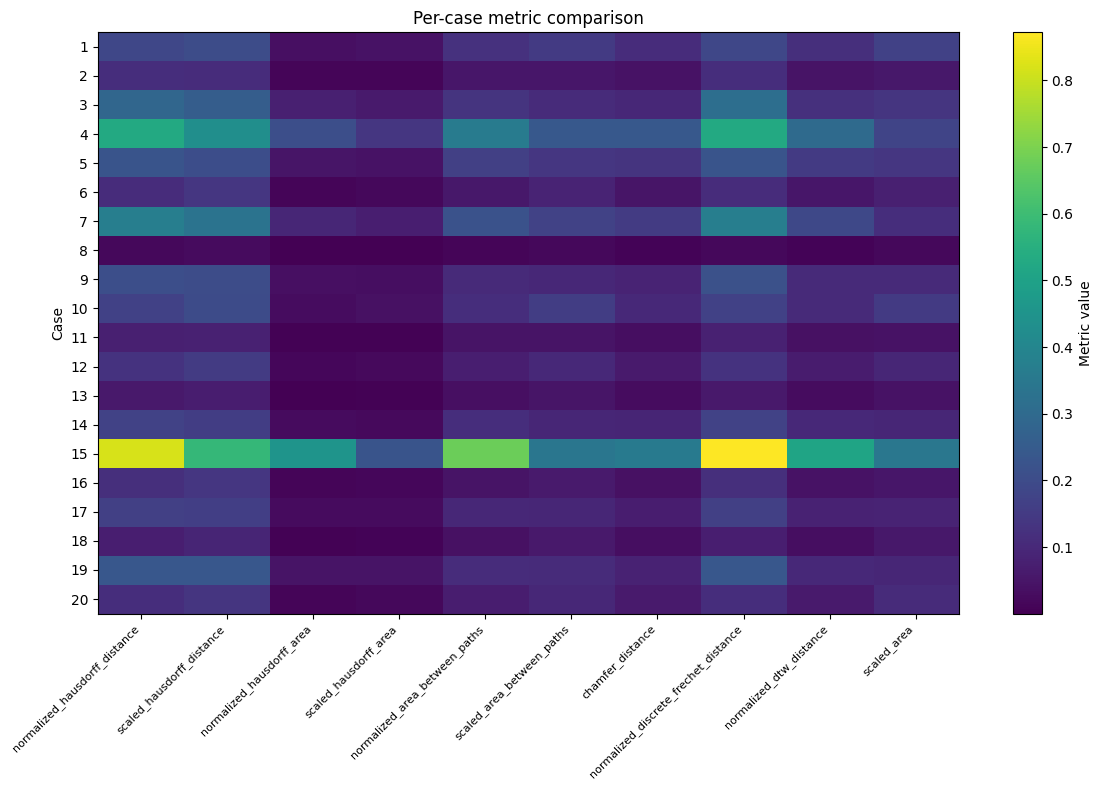

In [16]:
# Compare all metrics per sample (including both path lengths)
comparison_df = results_df.copy()
comparison_df["length_ratio"] = comparison_df["path1_length"] / comparison_df["path2_length"].replace(0, np.nan)
comparison_df["length_diff"] = comparison_df["path1_length"] - comparison_df["path2_length"]

display(comparison_df[["case", "path1_length", "path2_length", "length_ratio", "length_diff"] + metric_cols])

# Heatmap of metrics per case
metric_matrix = comparison_df[metric_cols].to_numpy()
fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(metric_matrix, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(metric_cols)))
ax.set_xticklabels(metric_cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(comparison_df)))
ax.set_yticklabels(comparison_df["case"].tolist())
ax.set_ylabel("Case")
ax.set_title("Per-case metric comparison")
plt.colorbar(im, ax=ax, label="Metric value")
plt.tight_layout()
plt.show()

In [17]:
# Summary statistics for all metrics
print("Summary Statistics for All Metrics:")
print("=" * 60)
for col in metric_cols:
    print(f"\n{col}:")
    print(f"  Mean:   {results_df[col].mean():.4f}")
    print(f"  Std:    {results_df[col].std():.4f}")
    print(f"  Min:    {results_df[col].min():.4f}")
    print(f"  Max:    {results_df[col].max():.4f}")
    print(f"  Median: {results_df[col].median():.4f}")

Summary Statistics for All Metrics:

normalized_hausdorff_distance:
  Mean:   0.2095
  Std:    0.1850
  Min:    0.0196
  Max:    0.8185
  Median: 0.1678

scaled_hausdorff_distance:
  Mean:   0.1958
  Std:    0.1297
  Min:    0.0264
  Max:    0.5816
  Median: 0.1615

normalized_hausdorff_area:
  Mean:   0.0579
  Std:    0.1036
  Min:    0.0004
  Max:    0.4499
  Median: 0.0267

scaled_hausdorff_area:
  Mean:   0.0430
  Std:    0.0535
  Min:    0.0007
  Max:    0.2272
  Median: 0.0242

normalized_area_between_paths:
  Mean:   0.1324
  Std:    0.1503
  Min:    0.0108
  Max:    0.6769
  Median: 0.1007

scaled_area_between_paths:
  Mean:   0.1141
  Std:    0.0741
  Min:    0.0194
  Max:    0.3418
  Median: 0.0965

chamfer_distance:
  Mean:   0.0941
  Std:    0.0817
  Min:    0.0074
  Max:    0.3610
  Median: 0.0769

normalized_discrete_frechet_distance:
  Mean:   0.2142
  Std:    0.1950
  Min:    0.0196
  Max:    0.8721
  Median: 0.1683

normalized_dtw_distance:
  Mean:   0.1132
  Std:    0

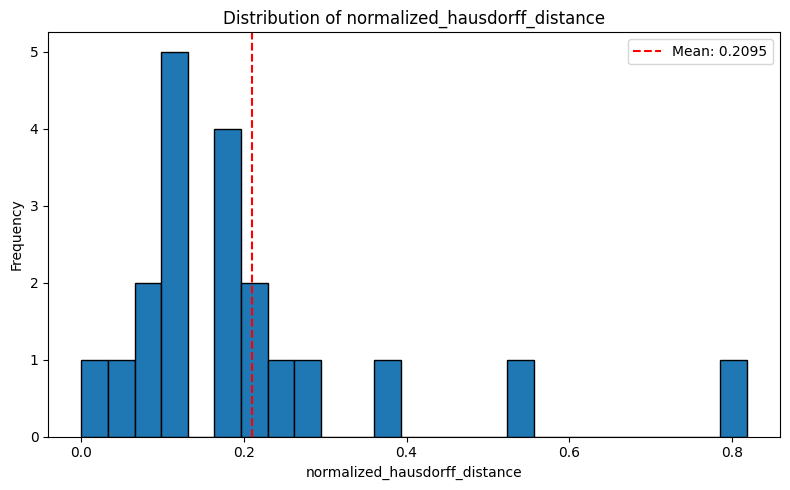

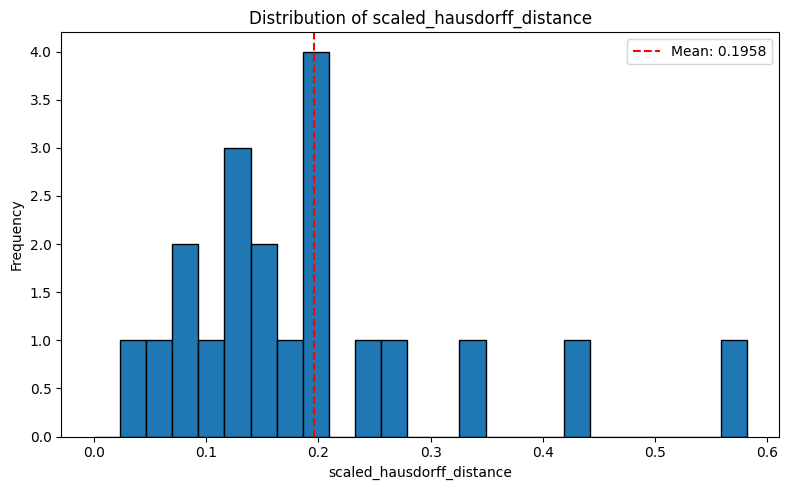

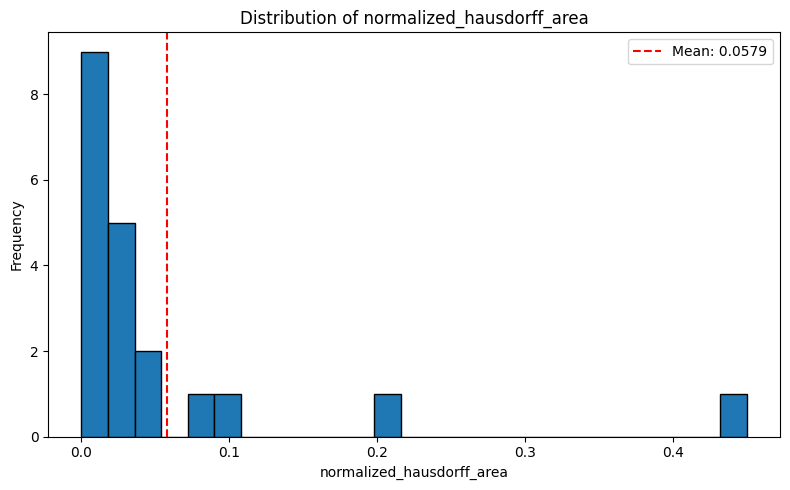

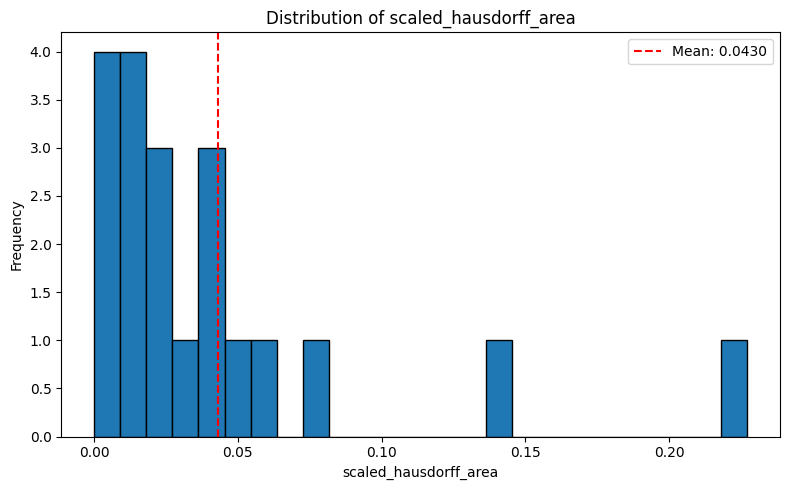

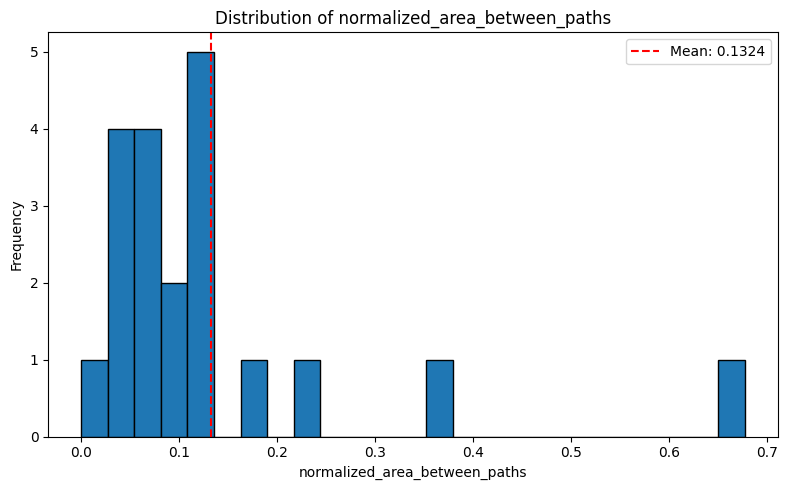

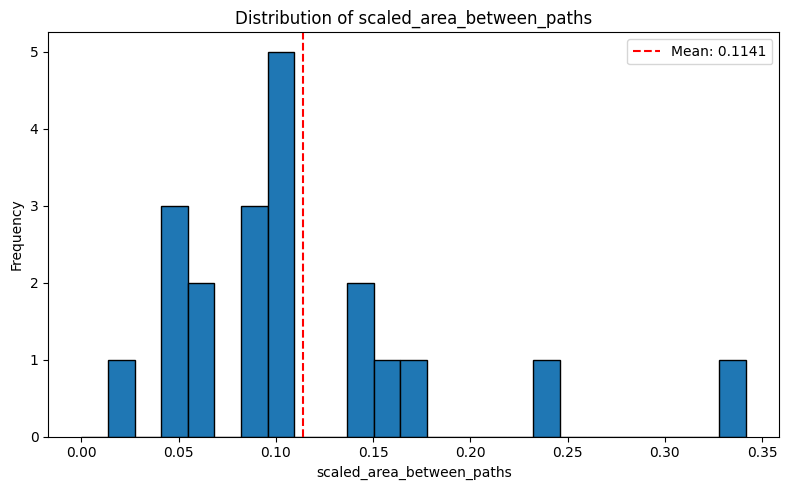

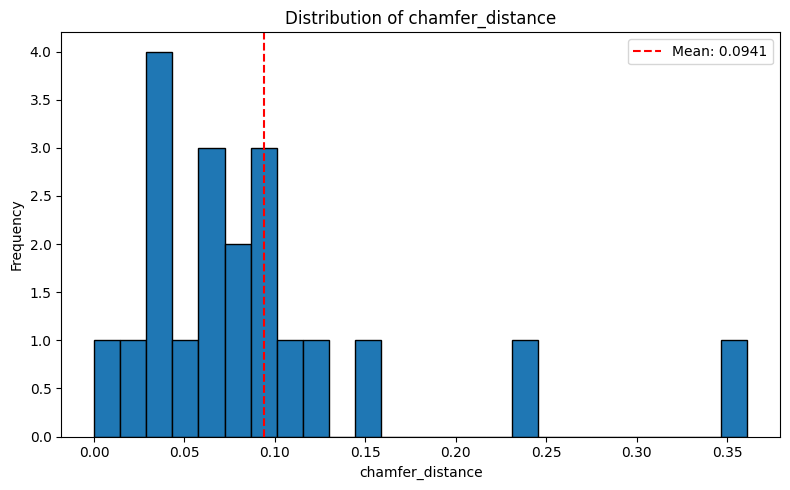

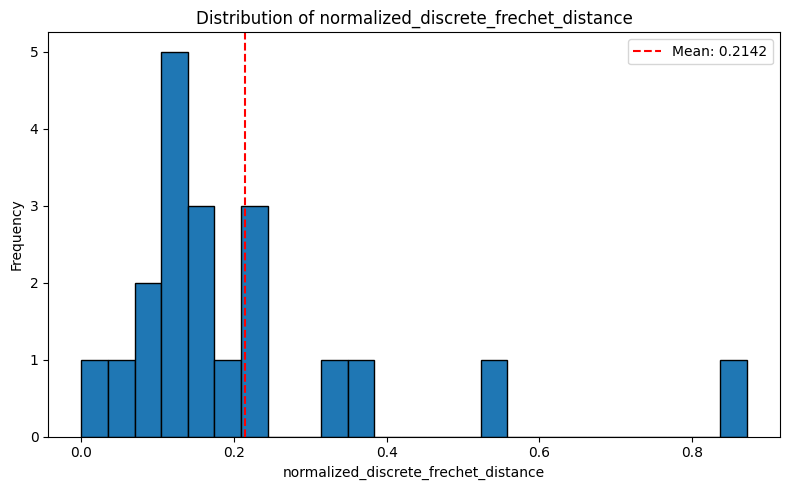

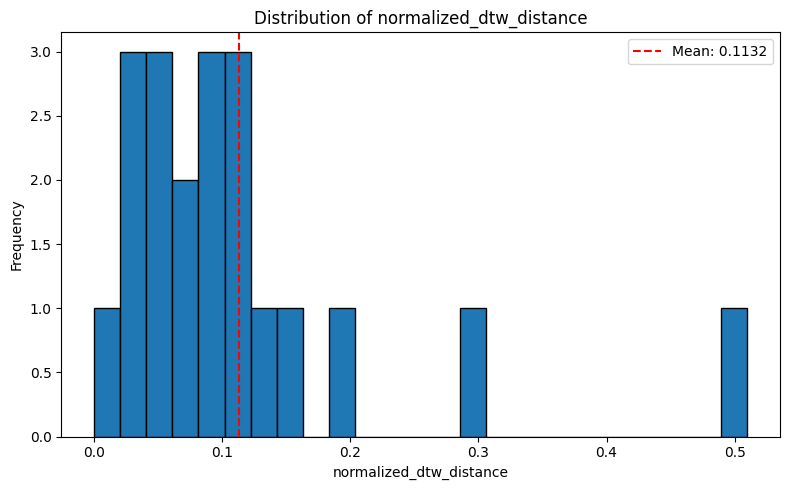

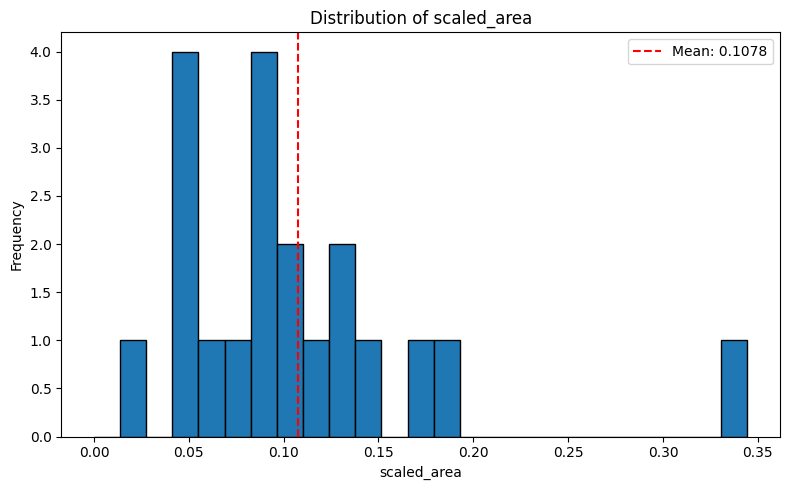

In [18]:
# Histograms of all metrics
for col in metric_cols:
    max_val = max(results_df[col].max(), 1e-6)
    mean_val = results_df[col].mean()

    plt.figure(figsize=(8, 5))
    plt.hist(results_df[col], bins=25, range=(0, max_val), edgecolor="black")
    plt.axvline(mean_val, color="red", linestyle="--", label=f"Mean: {mean_val:.4f}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {col}")
    plt.legend()
    plt.tight_layout()
    plt.show()

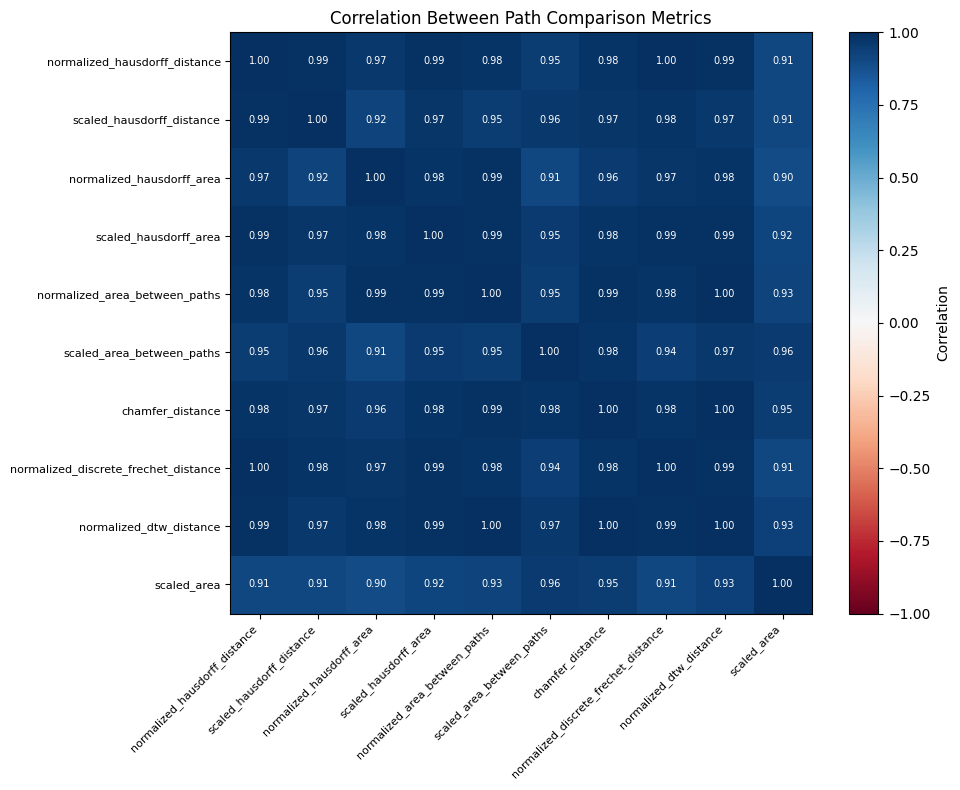

In [19]:
# Correlation heatmap of all metrics
corr_matrix = results_df[metric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix.values, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(metric_cols)))
ax.set_xticklabels(metric_cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(metric_cols)))
ax.set_yticklabels(metric_cols, fontsize=8)
ax.set_title("Correlation Between Path Comparison Metrics")

# Add correlation values as text
for i in range(len(metric_cols)):
    for j in range(len(metric_cols)):
        text = ax.text(
            j,
            i,
            f"{corr_matrix.values[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="black" if abs(corr_matrix.values[i, j]) < 0.5 else "white",
        )

plt.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

## Visualize Sample Cases (after metrics)

Show a few example cases using the already-computed paths and metrics.

Metric labels:
  0: normalized_hausdorff_distance
  1: scaled_hausdorff_distance
  2: normalized_hausdorff_area
  3: scaled_hausdorff_area
  4: normalized_area_between_paths
  5: scaled_area_between_paths
  6: chamfer_distance
  7: normalized_discrete_frechet_distance
  8: normalized_dtw_distance
  9: scaled_area


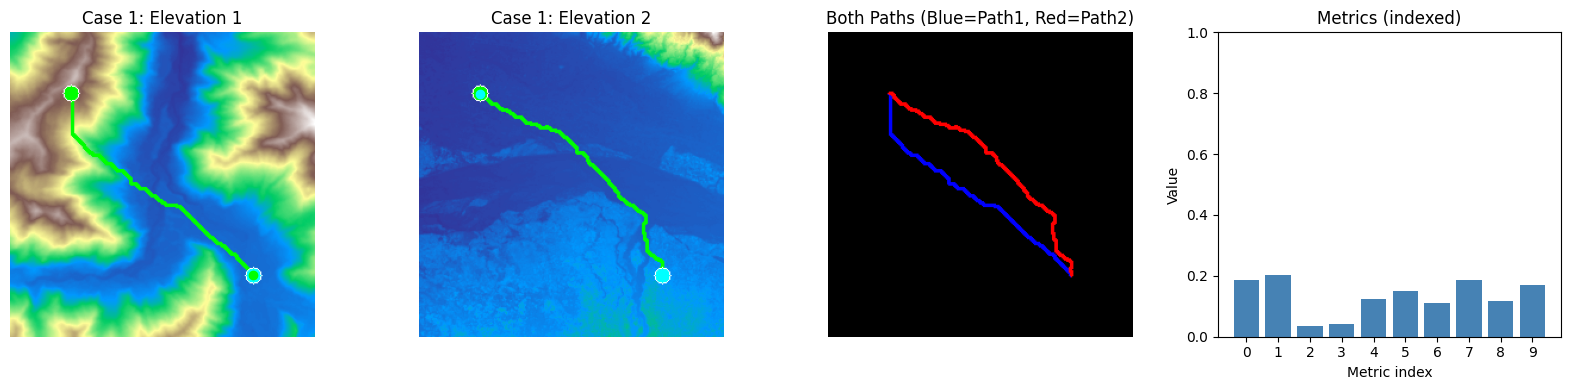


Case 1 metrics:
  normalized_hausdorff_distance: 0.1870
  scaled_hausdorff_distance: 0.2038
  normalized_hausdorff_area: 0.0348
  scaled_hausdorff_area: 0.0414
  normalized_area_between_paths: 0.1251
  scaled_area_between_paths: 0.1486
  chamfer_distance: 0.1100
  normalized_discrete_frechet_distance: 0.1870
  normalized_dtw_distance: 0.1176
  scaled_area: 0.1686


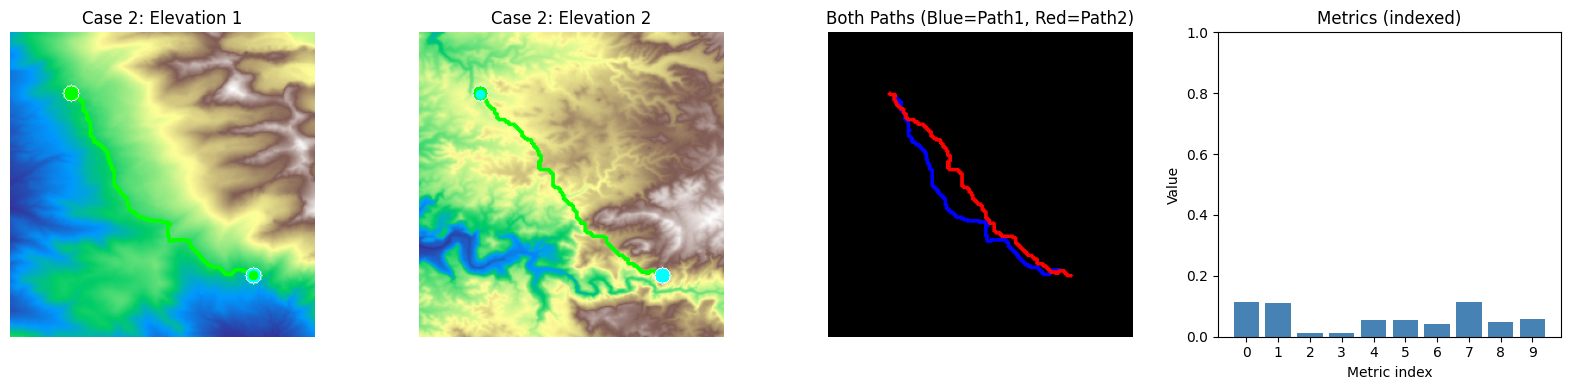


Case 2 metrics:
  normalized_hausdorff_distance: 0.1128
  scaled_hausdorff_distance: 0.1122
  normalized_hausdorff_area: 0.0119
  scaled_hausdorff_area: 0.0118
  normalized_area_between_paths: 0.0545
  scaled_area_between_paths: 0.0539
  chamfer_distance: 0.0429
  normalized_discrete_frechet_distance: 0.1128
  normalized_dtw_distance: 0.0475
  scaled_area: 0.0569


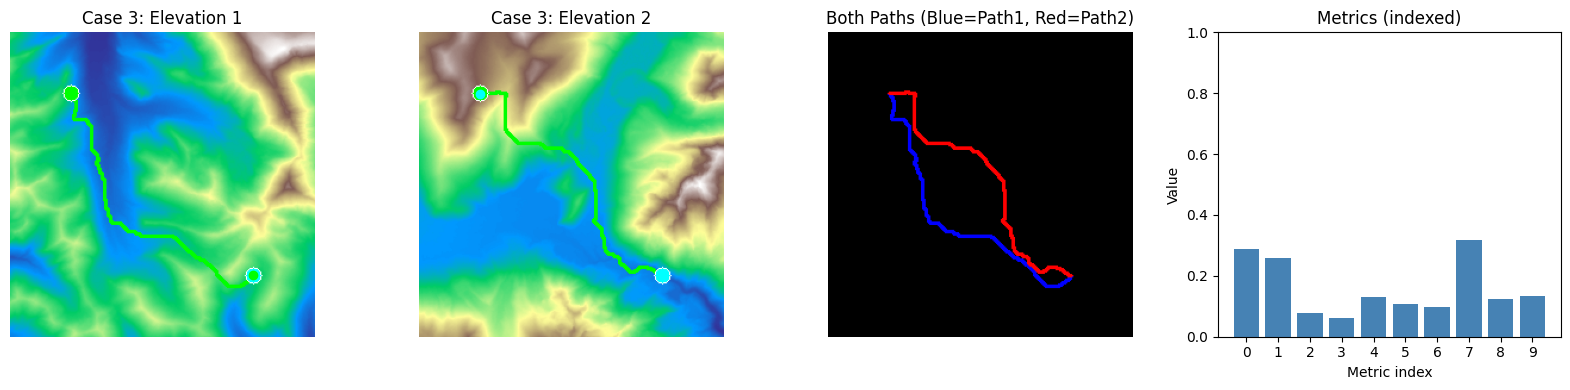


Case 3 metrics:
  normalized_hausdorff_distance: 0.2867
  scaled_hausdorff_distance: 0.2585
  normalized_hausdorff_area: 0.0768
  scaled_hausdorff_area: 0.0625
  normalized_area_between_paths: 0.1309
  scaled_area_between_paths: 0.1064
  chamfer_distance: 0.0986
  normalized_discrete_frechet_distance: 0.3164
  normalized_dtw_distance: 0.1224
  scaled_area: 0.1339


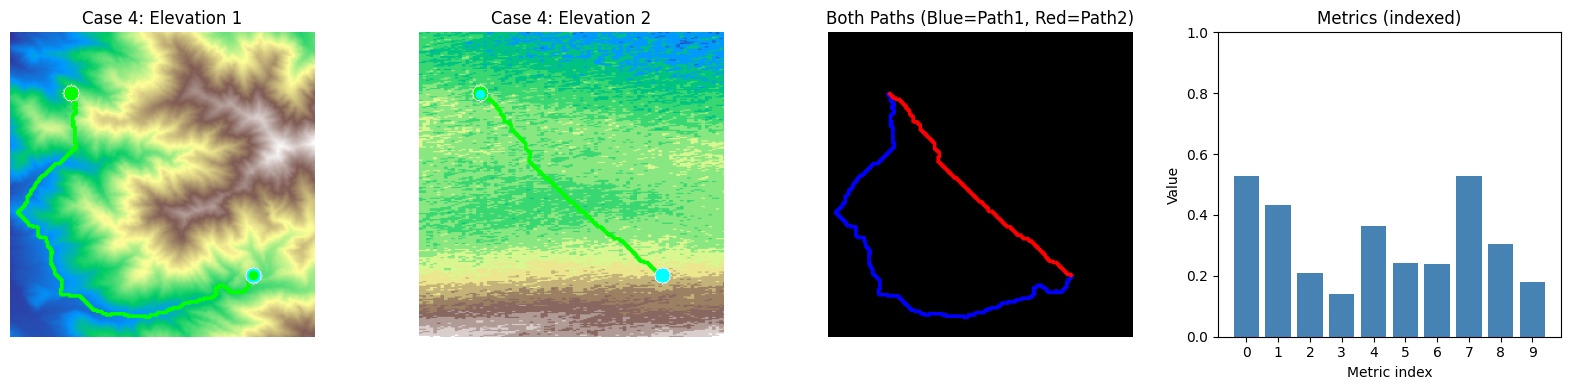


Case 4 metrics:
  normalized_hausdorff_distance: 0.5294
  scaled_hausdorff_distance: 0.4315
  normalized_hausdorff_area: 0.2090
  scaled_hausdorff_area: 0.1388
  normalized_area_between_paths: 0.3631
  scaled_area_between_paths: 0.2412
  chamfer_distance: 0.2396
  normalized_discrete_frechet_distance: 0.5294
  normalized_dtw_distance: 0.3034
  scaled_area: 0.1796


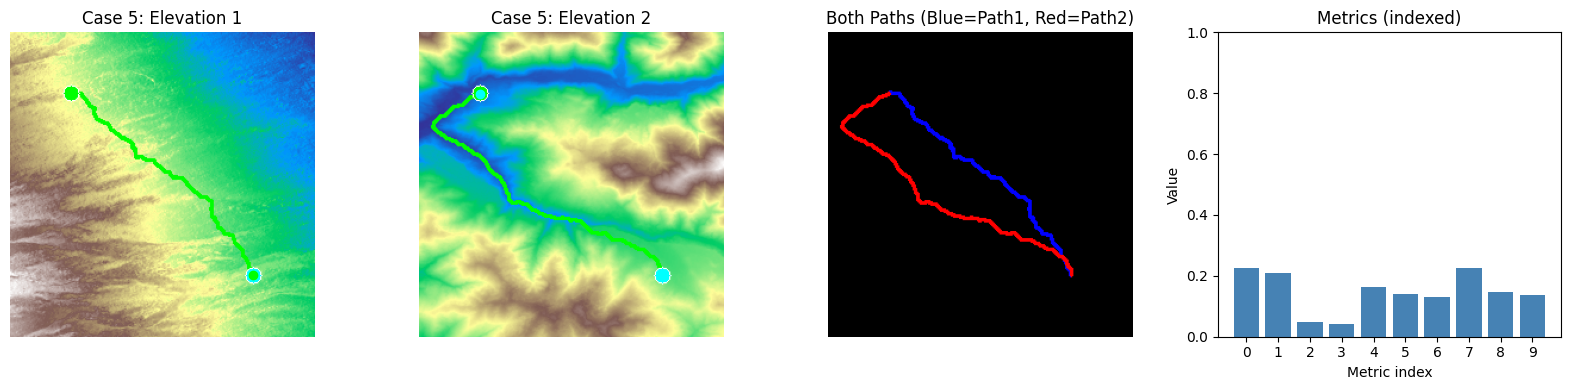


Case 5 metrics:
  normalized_hausdorff_distance: 0.2257
  scaled_hausdorff_distance: 0.2078
  normalized_hausdorff_area: 0.0497
  scaled_hausdorff_area: 0.0421
  normalized_area_between_paths: 0.1640
  scaled_area_between_paths: 0.1390
  chamfer_distance: 0.1298
  normalized_discrete_frechet_distance: 0.2257
  normalized_dtw_distance: 0.1469
  scaled_area: 0.1372


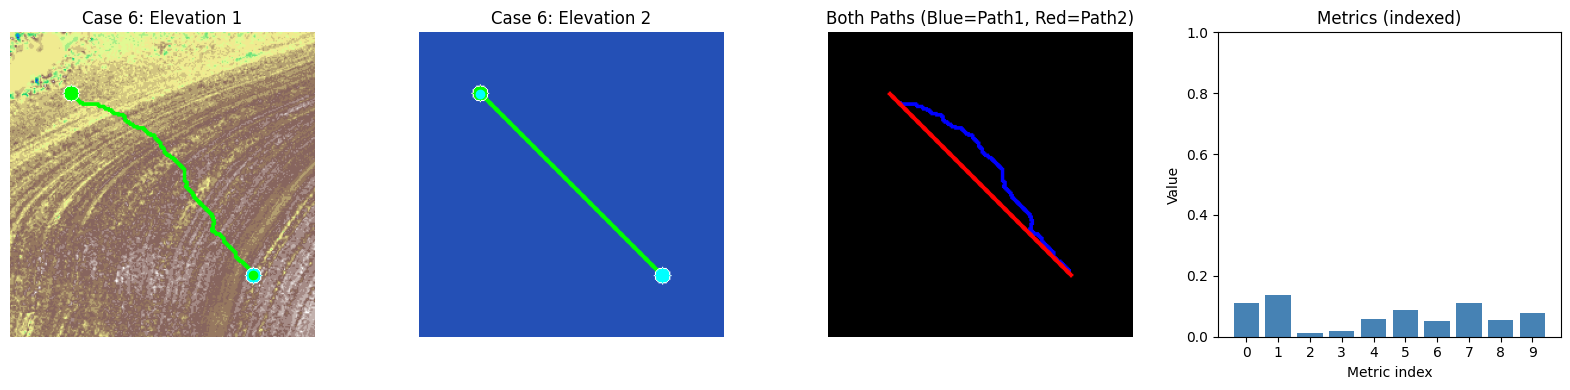


Case 6 metrics:
  normalized_hausdorff_distance: 0.1111
  scaled_hausdorff_distance: 0.1374
  normalized_hausdorff_area: 0.0117
  scaled_hausdorff_area: 0.0179
  normalized_area_between_paths: 0.0574
  scaled_area_between_paths: 0.0877
  chamfer_distance: 0.0514
  normalized_discrete_frechet_distance: 0.1111
  normalized_dtw_distance: 0.0537
  scaled_area: 0.0785


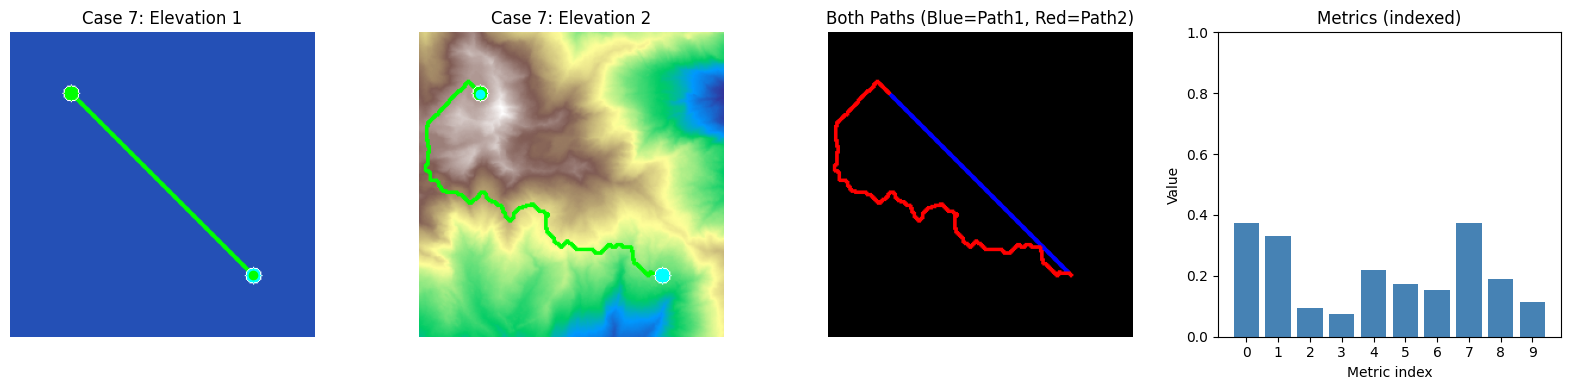


Case 7 metrics:
  normalized_hausdorff_distance: 0.3725
  scaled_hausdorff_distance: 0.3310
  normalized_hausdorff_area: 0.0932
  scaled_hausdorff_area: 0.0736
  normalized_area_between_paths: 0.2198
  scaled_area_between_paths: 0.1736
  chamfer_distance: 0.1525
  normalized_discrete_frechet_distance: 0.3725
  normalized_dtw_distance: 0.1894
  scaled_area: 0.1153


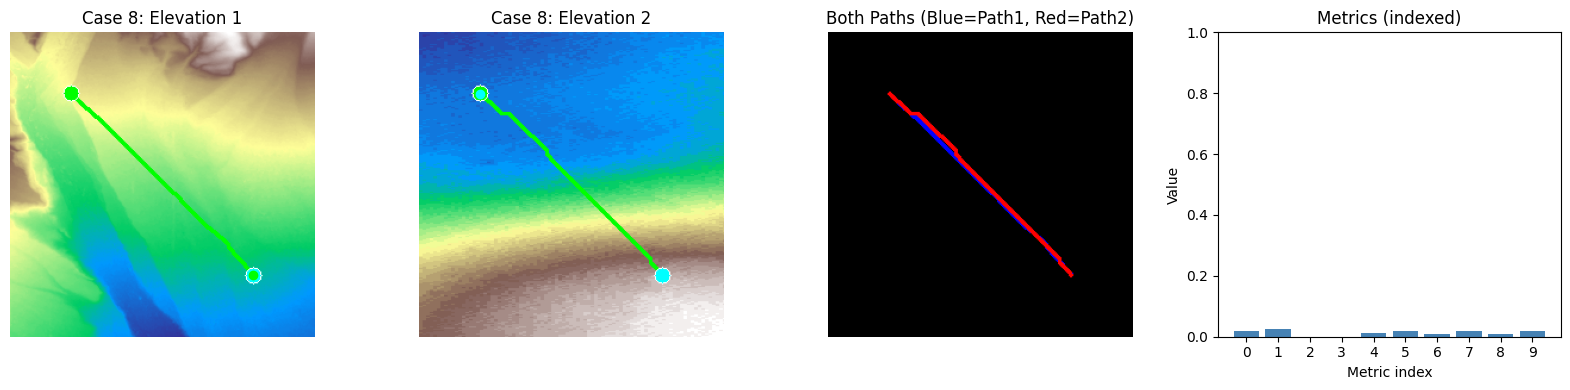


Case 8 metrics:
  normalized_hausdorff_distance: 0.0196
  scaled_hausdorff_distance: 0.0264
  normalized_hausdorff_area: 0.0004
  scaled_hausdorff_area: 0.0007
  normalized_area_between_paths: 0.0108
  scaled_area_between_paths: 0.0194
  chamfer_distance: 0.0074
  normalized_discrete_frechet_distance: 0.0196
  normalized_dtw_distance: 0.0077
  scaled_area: 0.0197


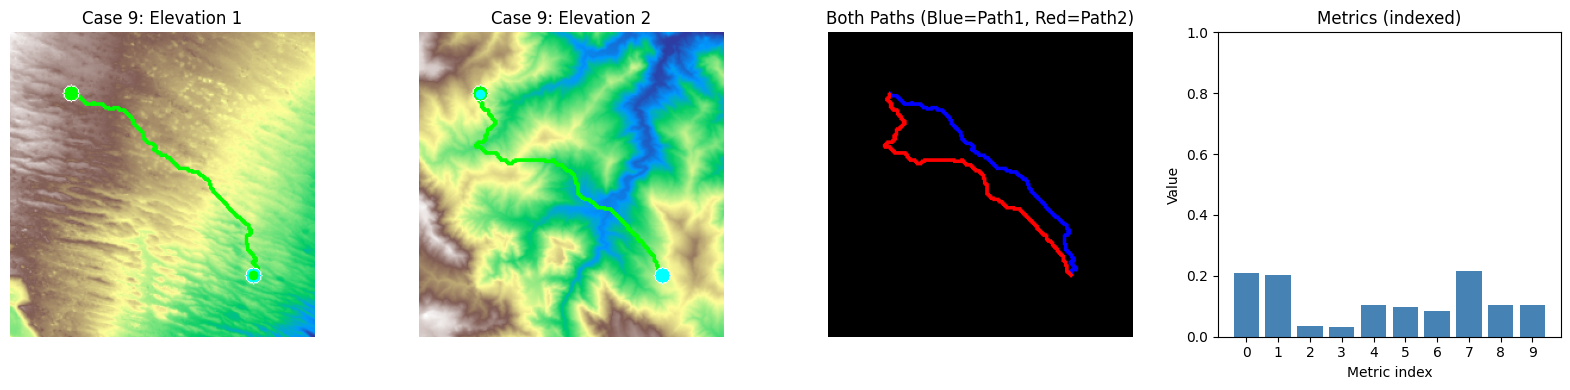


Case 9 metrics:
  normalized_hausdorff_distance: 0.2090
  scaled_hausdorff_distance: 0.2019
  normalized_hausdorff_area: 0.0351
  scaled_hausdorff_area: 0.0328
  normalized_area_between_paths: 0.1038
  scaled_area_between_paths: 0.0969
  chamfer_distance: 0.0855
  normalized_discrete_frechet_distance: 0.2158
  normalized_dtw_distance: 0.1042
  scaled_area: 0.1049


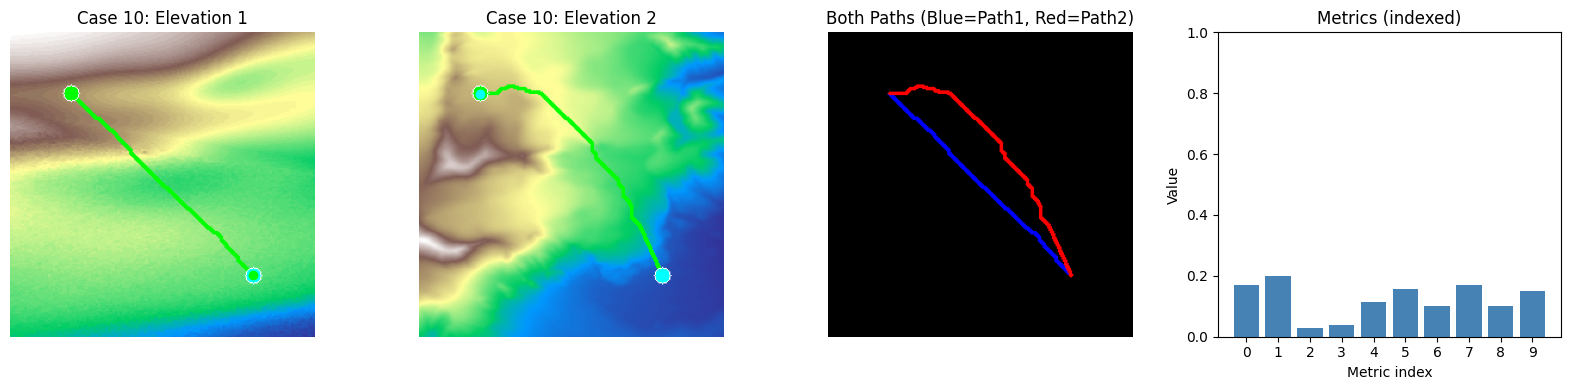


Case 10 metrics:
  normalized_hausdorff_distance: 0.1699
  scaled_hausdorff_distance: 0.1998
  normalized_hausdorff_area: 0.0289
  scaled_hausdorff_area: 0.0399
  normalized_area_between_paths: 0.1144
  scaled_area_between_paths: 0.1582
  chamfer_distance: 0.1004
  normalized_discrete_frechet_distance: 0.1699
  normalized_dtw_distance: 0.1026
  scaled_area: 0.1488


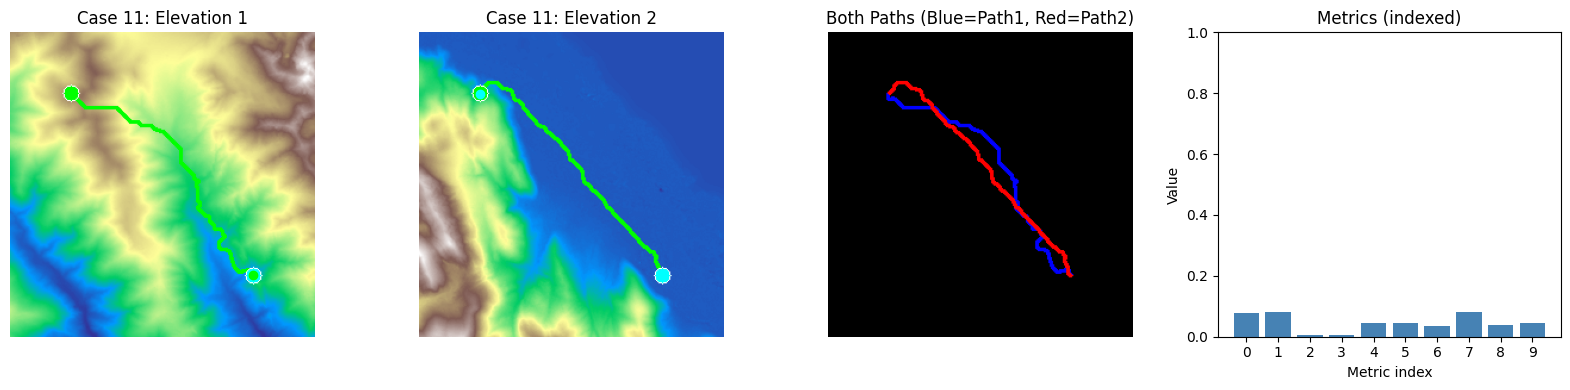


Case 11 metrics:
  normalized_hausdorff_distance: 0.0786
  scaled_hausdorff_distance: 0.0798
  normalized_hausdorff_area: 0.0062
  scaled_hausdorff_area: 0.0064
  normalized_area_between_paths: 0.0447
  scaled_area_between_paths: 0.0461
  chamfer_distance: 0.0341
  normalized_discrete_frechet_distance: 0.0818
  normalized_dtw_distance: 0.0383
  scaled_area: 0.0437


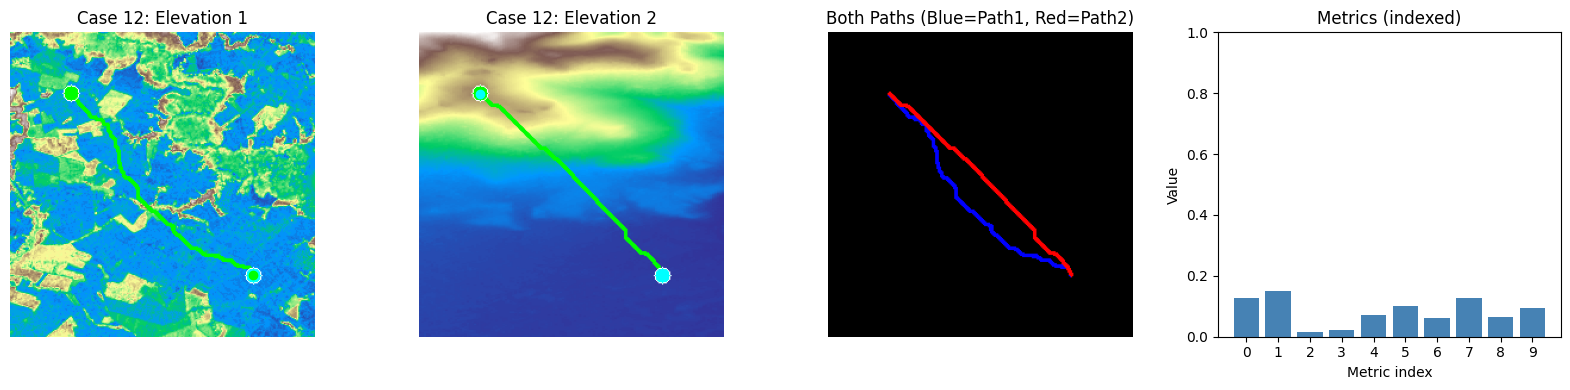


Case 12 metrics:
  normalized_hausdorff_distance: 0.1285
  scaled_hausdorff_distance: 0.1507
  normalized_hausdorff_area: 0.0162
  scaled_hausdorff_area: 0.0223
  normalized_area_between_paths: 0.0722
  scaled_area_between_paths: 0.0994
  chamfer_distance: 0.0630
  normalized_discrete_frechet_distance: 0.1285
  normalized_dtw_distance: 0.0656
  scaled_area: 0.0943


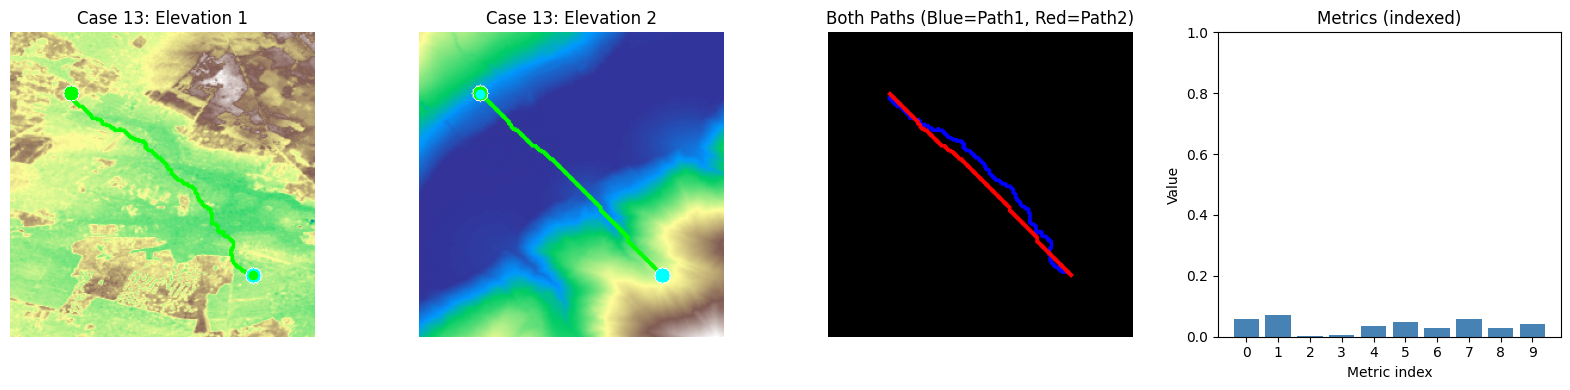


Case 13 metrics:
  normalized_hausdorff_distance: 0.0588
  scaled_hausdorff_distance: 0.0697
  normalized_hausdorff_area: 0.0032
  scaled_hausdorff_area: 0.0045
  normalized_area_between_paths: 0.0347
  scaled_area_between_paths: 0.0488
  chamfer_distance: 0.0288
  normalized_discrete_frechet_distance: 0.0588
  normalized_dtw_distance: 0.0300
  scaled_area: 0.0415


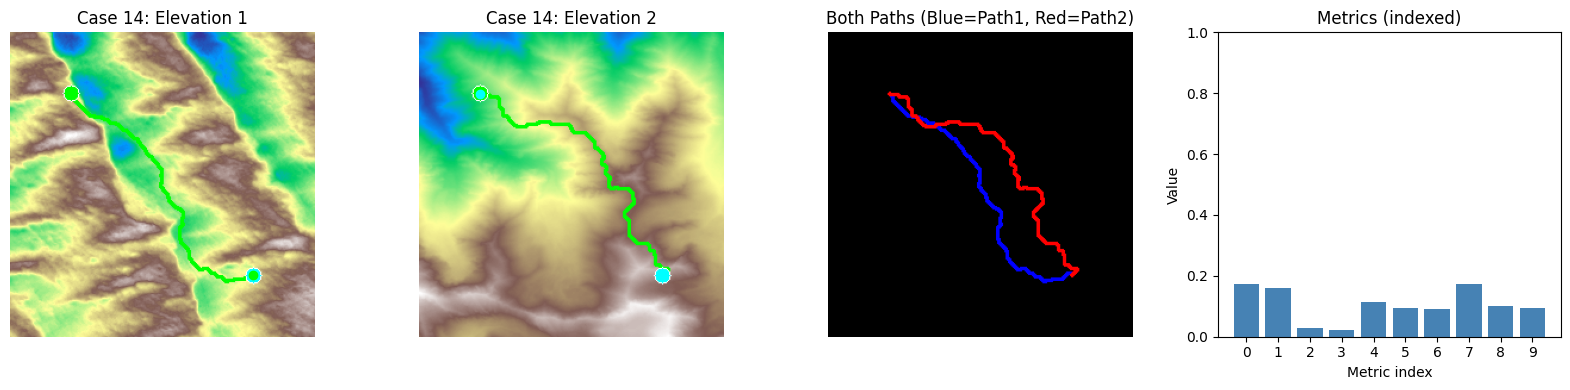


Case 14 metrics:
  normalized_hausdorff_distance: 0.1737
  scaled_hausdorff_distance: 0.1592
  normalized_hausdorff_area: 0.0274
  scaled_hausdorff_area: 0.0230
  normalized_area_between_paths: 0.1135
  scaled_area_between_paths: 0.0954
  chamfer_distance: 0.0903
  normalized_discrete_frechet_distance: 0.1737
  normalized_dtw_distance: 0.1019
  scaled_area: 0.0945


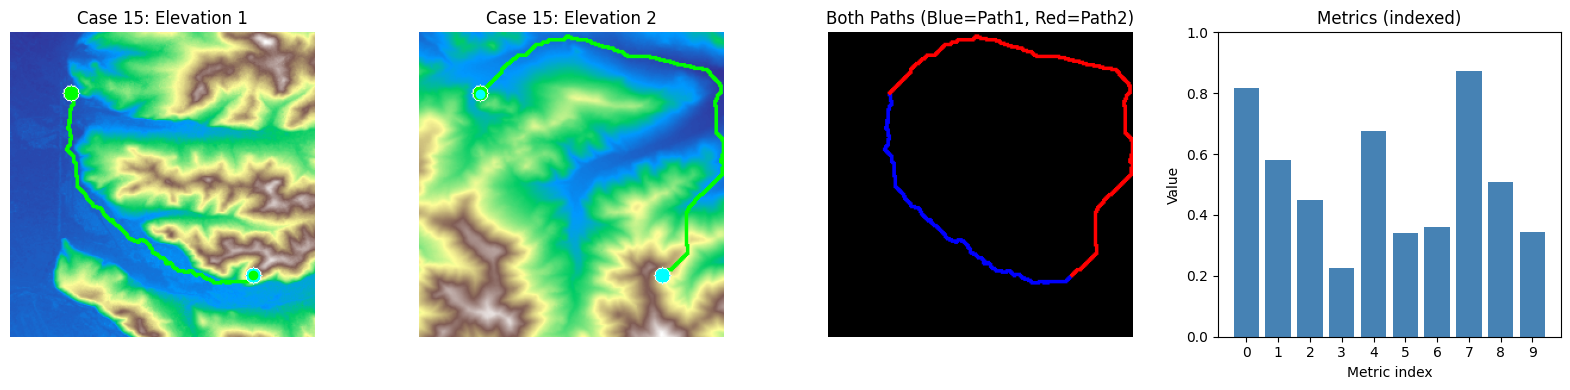


Case 15 metrics:
  normalized_hausdorff_distance: 0.8185
  scaled_hausdorff_distance: 0.5816
  normalized_hausdorff_area: 0.4499
  scaled_hausdorff_area: 0.2272
  normalized_area_between_paths: 0.6769
  scaled_area_between_paths: 0.3418
  chamfer_distance: 0.3610
  normalized_discrete_frechet_distance: 0.8721
  normalized_dtw_distance: 0.5099
  scaled_area: 0.3444


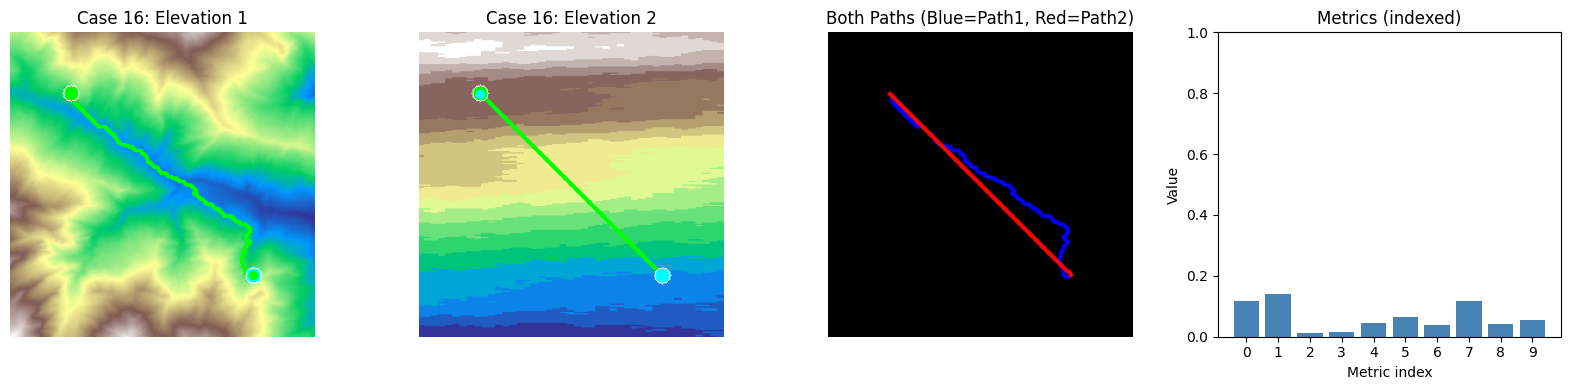


Case 16 metrics:
  normalized_hausdorff_distance: 0.1176
  scaled_hausdorff_distance: 0.1387
  normalized_hausdorff_area: 0.0117
  scaled_hausdorff_area: 0.0163
  normalized_area_between_paths: 0.0462
  scaled_area_between_paths: 0.0642
  chamfer_distance: 0.0393
  normalized_discrete_frechet_distance: 0.1176
  normalized_dtw_distance: 0.0432
  scaled_area: 0.0539


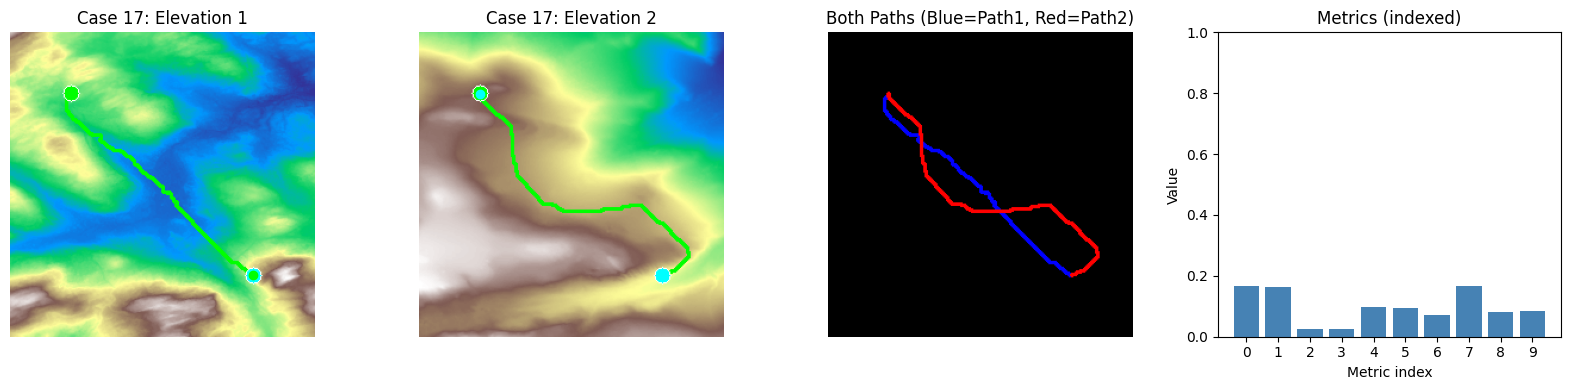


Case 17 metrics:
  normalized_hausdorff_distance: 0.1657
  scaled_hausdorff_distance: 0.1637
  normalized_hausdorff_area: 0.0260
  scaled_hausdorff_area: 0.0254
  normalized_area_between_paths: 0.0976
  scaled_area_between_paths: 0.0953
  chamfer_distance: 0.0713
  normalized_discrete_frechet_distance: 0.1667
  normalized_dtw_distance: 0.0823
  scaled_area: 0.0858


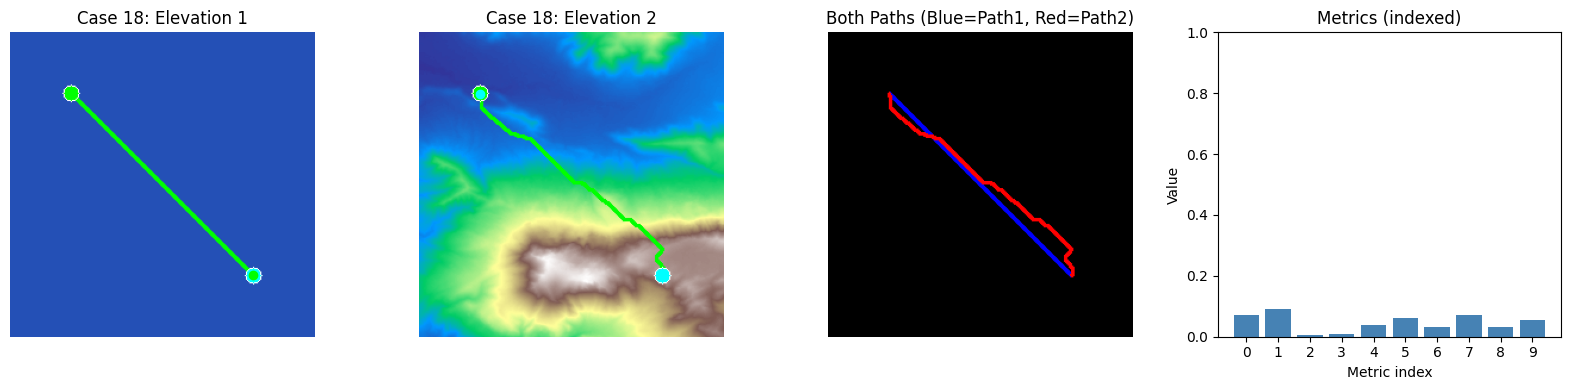


Case 18 metrics:
  normalized_hausdorff_distance: 0.0719
  scaled_hausdorff_distance: 0.0912
  normalized_hausdorff_area: 0.0052
  scaled_hausdorff_area: 0.0083
  normalized_area_between_paths: 0.0379
  scaled_area_between_paths: 0.0610
  chamfer_distance: 0.0323
  normalized_discrete_frechet_distance: 0.0719
  normalized_dtw_distance: 0.0334
  scaled_area: 0.0550


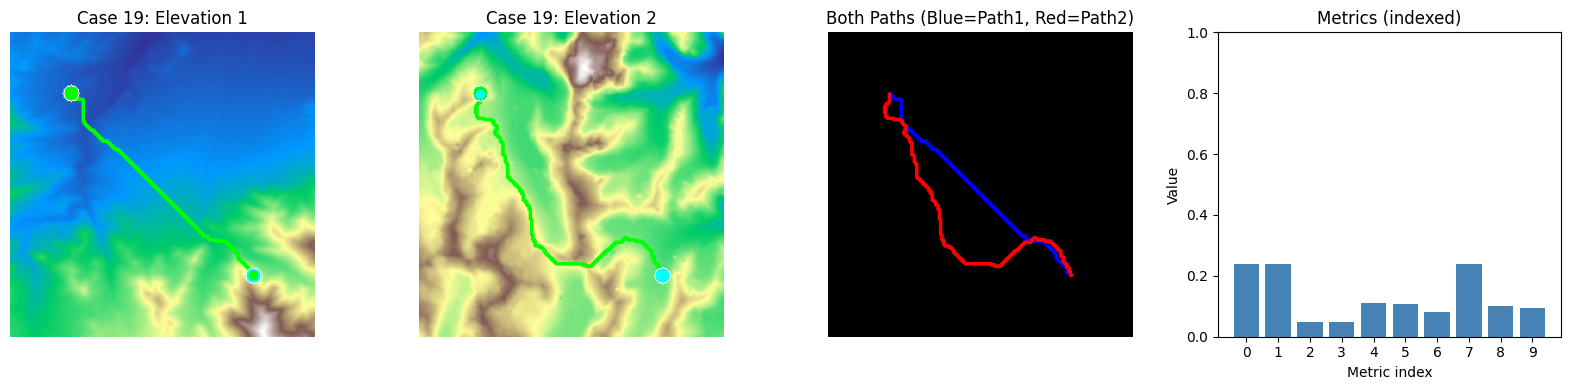


Case 19 metrics:
  normalized_hausdorff_distance: 0.2386
  scaled_hausdorff_distance: 0.2374
  normalized_hausdorff_area: 0.0476
  scaled_hausdorff_area: 0.0471
  normalized_area_between_paths: 0.1096
  scaled_area_between_paths: 0.1085
  chamfer_distance: 0.0826
  normalized_discrete_frechet_distance: 0.2386
  normalized_dtw_distance: 0.0994
  scaled_area: 0.0941


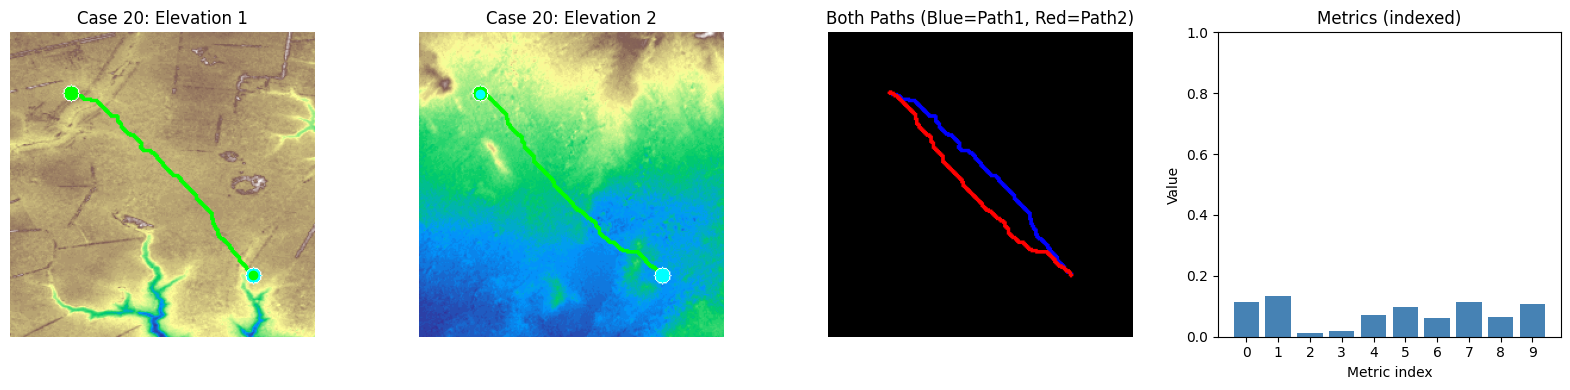


Case 20 metrics:
  normalized_hausdorff_distance: 0.1144
  scaled_hausdorff_distance: 0.1342
  normalized_hausdorff_area: 0.0131
  scaled_hausdorff_area: 0.0180
  normalized_area_between_paths: 0.0700
  scaled_area_between_paths: 0.0962
  chamfer_distance: 0.0619
  normalized_discrete_frechet_distance: 0.1144
  normalized_dtw_distance: 0.0644
  scaled_area: 0.1061


In [20]:
# Visualize selected cases using precomputed paths (with metric bar chart)
sample_cases = [c["case"] for c in cases]
case_map = {c["case"]: c for c in cases}
metrics_map = {r["case"]: r for r in results}

# Ensure metric_names includes all metric columns (adds our new metric)
metric_names = metric_cols

# Print metric labels beforehand (mapping from numeric label -> metric name)
print("Metric labels:")
for i, name in enumerate(metric_names):
    print(f"  {i}: {name}")

n_metrics = len(metric_names)

for case_id in sample_cases:
    c = case_map[case_id]
    r = metrics_map[case_id]
    path1 = c["path1"]
    path2 = c["path2"]
    crop1 = c["crop1"]
    crop2 = c["crop2"]
    start = c["start"]
    end = c["end"]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # Elevation 1
    img1 = make_vis_from_crop(crop1, path1, RESOLUTION)
    axes[0].imshow(img1)
    axes[0].plot([start[1], end[1]], [start[0], end[0]], "o", color="lime", markersize=6)
    axes[0].set_title(f"Case {case_id}: Elevation 1")
    axes[0].axis("off")

    # Elevation 2
    img2 = make_vis_from_crop(crop2, path2, RESOLUTION)
    axes[1].imshow(img2)
    axes[1].plot([start[1], end[1]], [start[0], end[0]], "o", color="cyan", markersize=6)
    axes[1].set_title(f"Case {case_id}: Elevation 2")
    axes[1].axis("off")

    # Both Paths
    paths_img = draw_paths_on_black(path1, path2, RESOLUTION)
    axes[2].imshow(paths_img)
    axes[2].set_title("Both Paths (Blue=Path1, Red=Path2)")
    axes[2].axis("off")

    # Metrics bar chart
    vals = [float(r[name]) for name in metric_names]
    axes[3].bar(range(n_metrics), vals, color="steelblue")
    axes[3].set_xticks(range(n_metrics))
    axes[3].set_xticklabels([str(i) for i in range(n_metrics)])
    axes[3].set_ylim(0, 1)
    axes[3].set_title("Metrics (indexed)")
    axes[3].set_xlabel("Metric index")
    axes[3].set_ylabel("Value")

    plt.tight_layout()
    plt.show()

    # Print metrics summary for the case
    print(f"\nCase {case_id} metrics:")
    for name in metric_names:
        print(f"  {name}: {r[name]:.4f}")